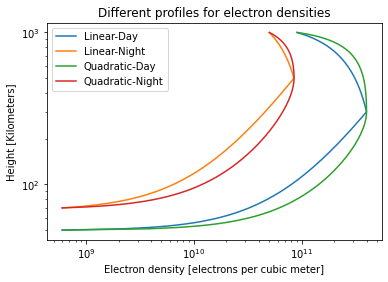

In [85]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patch
import scipy.optimize as optimize

# Electron density will change depending of daytime or nighttime

# Linear refraction index

def elec_dens_linear_day(r):
    '''Linear model for electron density distribution in Ionosphere'''
    if (r < 301):
        a = (4e11 - 6e8)/(300 - 50)
        b = 6e8 - a*50
        return a*r + b
    
    else:
        a = (9e10-4e11)/(1000-300)
        b = 9e10 - a*1000
        return a*r + b

def elec_dens_linear_night(r):
    '''Linear model for electron density distribution in Ionosphere at night'''
    if (r < 501):
        a = (8.5e10 - 6e8)/(500 - 70)
        b = 6e8 - a*70
        return a*r + b
    
    else:
        a = (5e10-8.5e10)/(1000-500)
        b = 8.5e10 - a*500
        return a*r + b
    
def elec_dens_quadratic_day(r):
    '''Second order polynomial function approximation for Ionesphere's electro density'''
    if (r < 301):
        x = 50.
        y = 6.e8
        xmax = 300 # Maximum electron density at 300 km
        ymax = 4.e11 # Maximum density during day
        # having a and c in func of b, using an extra point we can get b. The expression is
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)  
        c = ymax - b*xmax/2 # for condition given to a b has be this
        a = -1.*b/(2.*xmax) # condition to get the max in this point
        return a*r*r + b*r + c
    else :
        x = 1000.
        y = 9.e10
        xmax = 300 # Maximum electron density at 300 km
        ymax = 4.e11 # Maximum density during day
        # having a and c in func of b, using an extra point we can get b. The expression is
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)  
        c = ymax - b*xmax/2 # for condition given to a b has be this
        a = -1.*b/(2.*xmax) # condition to get the max in this point
        return a*r*r + b*r + c

def elec_dens_quadratic_night(r):
    '''Second order polynomial function approximation for Ionesphere's 
    electro density at night'''
    if (r < 501 ):
        x = 70.
        y = 6.e8
        xmax = 500 # Maximum electron density at 500 km
        ymax = 8.5e10 # Maximum density during night
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)
        c = ymax - b*xmax/2
        a = -1.*b/(2.*xmax)
        return a*r*r + b*r + c
    else :
        x = 1000.
        y = 5.e10
        xmax = 500 # Maximum electron density at 300 km
        ymax = 8.5e10 # Maximum density during day
        # having a and c in func of b, using an extra point we can get b. The expression is
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)  
        c = ymax - b*xmax/2 # for condition given to a b has be this
        a = -1.*b/(2.*xmax) # condition to get the max in this point
        return a*r*r + b*r + c


elec_dens_ld = []

for i in range(50,1000,1):
    elec_dens_ld.append(elec_dens_linear_day(i))
    
elec_dens_ln = []

for i in range(70,1000,1):
    elec_dens_ln.append(elec_dens_linear_night(i))


elec_dens_pd = []

for i in range(50,1000,1):
    elec_dens_pd.append(elec_dens_quadratic_day(i))
    
elec_dens_pn = []

for i in range(70,1000,1):
    elec_dens_pn.append(elec_dens_quadratic_night(i))

plt.loglog(elec_dens_ld,np.linspace(50,1000,950))
plt.loglog(elec_dens_ln,np.linspace(70,1000,930))
plt.loglog(elec_dens_pd,np.linspace(50,1000,950))
plt.loglog(elec_dens_pn,np.linspace(70,1000,930))

plt.xlabel("Electron density [electrons per cubic meter]")
plt.ylabel("Height [Kilometers]")
plt.title("Different profiles for electron densities")
plt.legend(["Linear-Day","Linear-Night","Quadratic-Day","Quadratic-Night"])


def ref_index(freq,elec_dens,parameter = [-1,-1],delta = 0):
    total_y = 1200
    N = np.zeros(total_y) # Refraction index

    # First 80 km the refraction index will be 1 (air ref. index approx 1)
    
    for i in range(0,50,1):
        N[i] = 1

    vacuum_permittivity = 8.854e-12 # Permittivity of free space in Faradays over meters
    e_charge = -1.602e-19 # Electron charge in Coulombs
    e_mass = 9.10938356e-31 # Electron mass in Kilograms
    
# The electron density has to be given in units of meters^(-3)

    for i in range(50,total_y,1):
        if (i>=parameter[0] and i<=parameter[1]):
            pl_freq = np.sqrt(((elec_dens(i)+delta)*e_charge*e_charge)/(e_mass*vacuum_permittivity))
        else:
            pl_freq = np.sqrt((elec_dens(i)*e_charge*e_charge)/(e_mass*vacuum_permittivity))
        
        if (pl_freq >= freq):
            N[i] = 0
        else:
            N[i] = np.sqrt(1 - (pl_freq/freq)**2)

    return N



In [82]:
for i in range(0,1200,1):
    print("At km ", i ,"ref index is: ",ref_index(1.e8, elec_dens_linear_day,[100,110],5e11)[i])
#print("Refraction index linear night ",ref_index(1.e7, elec_dens_linear_night))
#print("Refraction index quad day ",ref_index(1.e7,elec_dens_quadratic_day))
#print("Refraction index quad night ",ref_index(1.e7,elec_dens_quadratic_night))

At km  0 ref index is:  1.0
At km  1 ref index is:  1.0
At km  2 ref index is:  1.0
At km  3 ref index is:  1.0
At km  4 ref index is:  1.0
At km  5 ref index is:  1.0
At km  6 ref index is:  1.0
At km  7 ref index is:  1.0
At km  8 ref index is:  1.0
At km  9 ref index is:  1.0
At km  10 ref index is:  1.0
At km  11 ref index is:  1.0
At km  12 ref index is:  1.0
At km  13 ref index is:  1.0
At km  14 ref index is:  1.0
At km  15 ref index is:  1.0
At km  16 ref index is:  1.0
At km  17 ref index is:  1.0
At km  18 ref index is:  1.0
At km  19 ref index is:  1.0
At km  20 ref index is:  1.0
At km  21 ref index is:  1.0
At km  22 ref index is:  1.0
At km  23 ref index is:  1.0
At km  24 ref index is:  1.0
At km  25 ref index is:  1.0
At km  26 ref index is:  1.0
At km  27 ref index is:  1.0
At km  28 ref index is:  1.0
At km  29 ref index is:  1.0
At km  30 ref index is:  1.0
At km  31 ref index is:  1.0
At km  32 ref index is:  1.0
At km  33 ref index is:  1.0
At km  34 ref index is: 

At km  244 ref index is:  0.949309636668821
At km  245 ref index is:  0.9490418506232876
At km  246 ref index is:  0.9487739889966739
At km  247 ref index is:  0.9485060517249463
At km  248 ref index is:  0.9482380387439813
At km  249 ref index is:  0.9479699499895649
At km  250 ref index is:  0.9477017853973917
At km  251 ref index is:  0.9474335449030659
At km  252 ref index is:  0.9471652284421
At km  253 ref index is:  0.9468968359499157
At km  254 ref index is:  0.9466283673618425
At km  255 ref index is:  0.9463598226131186
At km  256 ref index is:  0.9460912016388902
At km  257 ref index is:  0.9458225043742113
At km  258 ref index is:  0.9455537307540438
At km  259 ref index is:  0.9452848807132571
At km  260 ref index is:  0.9450159541866278
At km  261 ref index is:  0.9447469511088398
At km  262 ref index is:  0.9444778714144838
At km  263 ref index is:  0.9442087150380578
At km  264 ref index is:  0.9439394819139657
At km  265 ref index is:  0.9436701719765184
At km  266 ref

At km  452 ref index is:  0.9455899203357995
At km  453 ref index is:  0.9456644295924915
At km  454 ref index is:  0.9457389329790337
At km  455 ref index is:  0.945813430496813
At km  456 ref index is:  0.9458879221472164
At km  457 ref index is:  0.9459624079316299
At km  458 ref index is:  0.9460368878514389
At km  459 ref index is:  0.9461113619080287
At km  460 ref index is:  0.9461858301027836
At km  461 ref index is:  0.9462602924370874
At km  462 ref index is:  0.9463347489123238
At km  463 ref index is:  0.9464091995298755
At km  464 ref index is:  0.9464836442911247
At km  465 ref index is:  0.9465580831974534
At km  466 ref index is:  0.9466325162502426
At km  467 ref index is:  0.946706943450873
At km  468 ref index is:  0.9467813648007248
At km  469 ref index is:  0.9468557803011777
At km  470 ref index is:  0.9469301899536104
At km  471 ref index is:  0.9470045937594017
At km  472 ref index is:  0.9470789917199295
At km  473 ref index is:  0.9471533838365711
At km  474 r

At km  704 ref index is:  0.9641841724014677
At km  705 ref index is:  0.9642572448601732
At km  706 ref index is:  0.9643303117817881
At km  707 ref index is:  0.9644033731675711
At km  708 ref index is:  0.9644764290187802
At km  709 ref index is:  0.9645494793366729
At km  710 ref index is:  0.9646225241225065
At km  711 ref index is:  0.9646955633775374
At km  712 ref index is:  0.9647685971030219
At km  713 ref index is:  0.9648416253002157
At km  714 ref index is:  0.9649146479703739
At km  715 ref index is:  0.9649876651147512
At km  716 ref index is:  0.9650606767346019
At km  717 ref index is:  0.96513368283118
At km  718 ref index is:  0.9652066834057385
At km  719 ref index is:  0.9652796784595302
At km  720 ref index is:  0.9653526679938078
At km  721 ref index is:  0.9654256520098229
At km  722 ref index is:  0.9654986305088269
At km  723 ref index is:  0.9655716034920709
At km  724 ref index is:  0.9656445709608054
At km  725 ref index is:  0.96571753291628
At km  726 ref

At km  941 ref index is:  0.981350192256012
At km  942 ref index is:  0.9814219866075655
At km  943 ref index is:  0.9814937757075025
At km  944 ref index is:  0.9815655595569753
At km  945 ref index is:  0.9816373381571356
At km  946 ref index is:  0.9817091115091351
At km  947 ref index is:  0.9817808796141246
At km  948 ref index is:  0.9818526424732547
At km  949 ref index is:  0.9819244000876756
At km  950 ref index is:  0.9819961524585371
At km  951 ref index is:  0.9820678995869884
At km  952 ref index is:  0.9821396414741784
At km  953 ref index is:  0.9822113781212558
At km  954 ref index is:  0.9822831095293685
At km  955 ref index is:  0.9823548356996641
At km  956 ref index is:  0.9824265566332898
At km  957 ref index is:  0.9824982723313926
At km  958 ref index is:  0.9825699827951189
At km  959 ref index is:  0.9826416880256144
At km  960 ref index is:  0.9827133880240249
At km  961 ref index is:  0.9827850827914953
At km  962 ref index is:  0.9828567723291706
At km  963 

At km  1131 ref index is:  0.9948981010376742
At km  1132 ref index is:  0.9949689178080886
At km  1133 ref index is:  0.9950397295384882
At km  1134 ref index is:  0.9951105362299489
At km  1135 ref index is:  0.9951813378835463
At km  1136 ref index is:  0.9952521345003555
At km  1137 ref index is:  0.9953229260814516
At km  1138 ref index is:  0.9953937126279085
At km  1139 ref index is:  0.9954644941408006
At km  1140 ref index is:  0.9955352706212015
At km  1141 ref index is:  0.9956060420701842
At km  1142 ref index is:  0.995676808488822
At km  1143 ref index is:  0.995747569878187
At km  1144 ref index is:  0.9958183262393516
At km  1145 ref index is:  0.9958890775733874
At km  1146 ref index is:  0.9959598238813657
At km  1147 ref index is:  0.9960305651643577
At km  1148 ref index is:  0.9961013014234339
At km  1149 ref index is:  0.9961720326596644
At km  1150 ref index is:  0.9962427588741191
At km  1151 ref index is:  0.9963134800678674
At km  1152 ref index is:  0.9963841